# 03 · ¿Cuántas veces se multiplica el pueblo?

Cruzamos las estimaciones de afluencia (notebook 02) con la población de la cabecera (notebook 01). Como las cifras de afluencia son inciertas, no buscamos un número exacto sino un **rango robusto**: ¿el resultado cambia si cambiamos el denominador o la cifra de visitantes?

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import pandas as pd
import plotly.graph_objects as go

from src import config, tema
from src import procesamiento as proc

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

In [2]:
poblacion = pd.read_csv(config.DIR_PROCESSED / "poblacion_censal.csv")
proyeccion = pd.read_csv(config.DIR_PROCESSED / "proyeccion_coespo_magdalena.csv")
mag = poblacion[(poblacion["municipio"] == "Magdalena")].set_index("anio")

denominadores = {
    "Cabecera, Censo 2020": int(mag.loc[2020, "pob_cabecera"]),
    "Municipio, Censo 2020": int(mag.loc[2020, "pob_municipio"]),
    "Cabecera estimada 2025 (proyección)": int(proyeccion.loc[proyeccion["anio"] == 2025, "cabecera_estimada"].iloc[0]),
}
denominadores

{'Cabecera, Censo 2020': 30429,
 'Municipio, Censo 2020': 33049,
 'Cabecera estimada 2025 (proyección)': 32840}

## 1. Numeradores: estimaciones de visitantes totales

Usamos solo cifras de **visitantes totales** con fuente primaria. Se dejan fuera los conteos de caminantes (miden a otra población) y la referencia de "hasta doce mil" (no es una estimación del año).

In [3]:
prensa = proc.leer_registro_prensa()
visitantes = prensa[
    (prensa["que_mide"] == "visitantes_totales")
    & (prensa["momento"].isin(["balance", "proyeccion"]))
    & (prensa["verificacion"] == "primaria")
][["id", "anio_evento", "medio", "cifra_min", "cifra_max", "momento", "declarante"]]
visitantes

,id,anio_evento,medio,cifra_min,cifra_max,momento,declarante
2,P03,2023,El Imparcial,60000.0,60000.0,balance,René Flores Rivera
6,P07,2024,El Imparcial,150000.0,150000.0,proyeccion,Ricardo Revilla Acuña
12,P13,2026,El Diario de Sonora,100000.0,120000.0,proyeccion,Hipólito Sedano Ruiz


In [4]:
filas = []
for _, v in visitantes.iterrows():
    for nombre_den, den in denominadores.items():
        filas.append({
            "id": v["id"], "anio": v["anio_evento"], "momento": v["momento"],
            "visitantes": v["cifra_max"], "denominador": nombre_den, "poblacion": den,
            "veces": v["cifra_max"] / den,
        })
sensibilidad = pd.DataFrame(filas)
sensibilidad.pivot_table(index=["id", "anio", "momento", "visitantes"], columns="denominador", values="veces").round(2)

,,,denominador,Cabecera estimada 2025 (proyección),"Cabecera, Censo 2020","Municipio, Censo 2020"
id,anio,momento,visitantes,,,
P03,2023,balance,60000.0,1.83,1.97,1.82
P07,2024,proyeccion,150000.0,4.57,4.93,4.54
P13,2026,proyeccion,120000.0,3.65,3.94,3.63


In [5]:
rango = sensibilidad["veces"].agg(["min", "max"])
print(f"Rango del multiplicador con todas las combinaciones: {rango['min']:.2f}x a {rango['max']:.2f}x")
base = sensibilidad[sensibilidad["denominador"] == "Cabecera, Censo 2020"]
print(f"Con el denominador principal (cabecera 2020): {base['veces'].min():.2f}x a {base['veces'].max():.2f}x")

Rango del multiplicador con todas las combinaciones: 1.82x a 4.93x
Con el denominador principal (cabecera 2020): 1.97x a 4.93x


**El resultado es robusto:** con cualquier denominador razonable, las fiestas traen entre ~1.7 y ~5 veces la población del pueblo. Cambiar el denominador mueve el rango unas décimas; lo que más lo mueve es qué estimación de visitantes creemos.

## 2. Un matiz: no están todos al mismo tiempo

Los visitantes se reparten en 10-11 días. El dato que más se acerca a una "foto" simultánea es el de 2024: 45,000 personas en el primer fin de semana (tres días).

In [6]:
cab = denominadores["Cabecera, Censo 2020"]
fin_semana_2024 = 45000
print(f"Primer fin de semana 2024: {fin_semana_2024:,} personas = {fin_semana_2024 / cab:.2f} veces la cabecera en 3 días")
print(f"Promedio diario si fueran 60 mil en 11 días (2023): {60000 / 11:,.0f} personas/día = {60000 / 11 / cab:.0%} de la cabecera cada día")

Primer fin de semana 2024: 45,000 personas = 1.48 veces la cabecera en 3 días
Promedio diario si fueran 60 mil en 11 días (2023): 5,455 personas/día = 18% de la cabecera cada día


## 3. ¿Dónde caben?

Ponemos las estimaciones contra la infraestructura que el INEGI sí mide: hoteles y moteles en el DENUE (13 en el municipio, ver notebook 06) y viviendas de uso temporal en el censo 2020.

In [7]:
vivienda = pd.read_csv(config.DIR_PROCESSED / "vivienda_magdalena.csv").set_index("anio")
hoteles = 13
capacidad = pd.DataFrame({
    "indicador": ["Visitantes por hotel o motel", "Visitantes por vivienda de uso temporal", "Visitantes por vivienda habitada"],
    "con_60_mil": [60000 / hoteles, 60000 / vivienda.loc[2020, "viv_uso_temporal"], 60000 / vivienda.loc[2020, "viv_habitadas"]],
    "con_150_mil": [150000 / hoteles, 150000 / vivienda.loc[2020, "viv_uso_temporal"], 150000 / vivienda.loc[2020, "viv_habitadas"]],
}).round(1)
capacidad

,indicador,con_60_mil,con_150_mil
0,Visitantes por hotel o motel,4615.4,11538.5
1,Visitantes por vivienda de uso temporal,85.6,214.0
2,Visitantes por vivienda habitada,6.6,16.5


Aun repartiendo a todos los visitantes en cada vivienda habitada del pueblo, tocarían entre 6 y 17 por casa. Por eso la prensa y la literatura académica describen campamentos en la orilla del río Magdalena.

## 4. Figura principal

Interactiva: outputs/figuras/03_multiplicador_poblacional.html


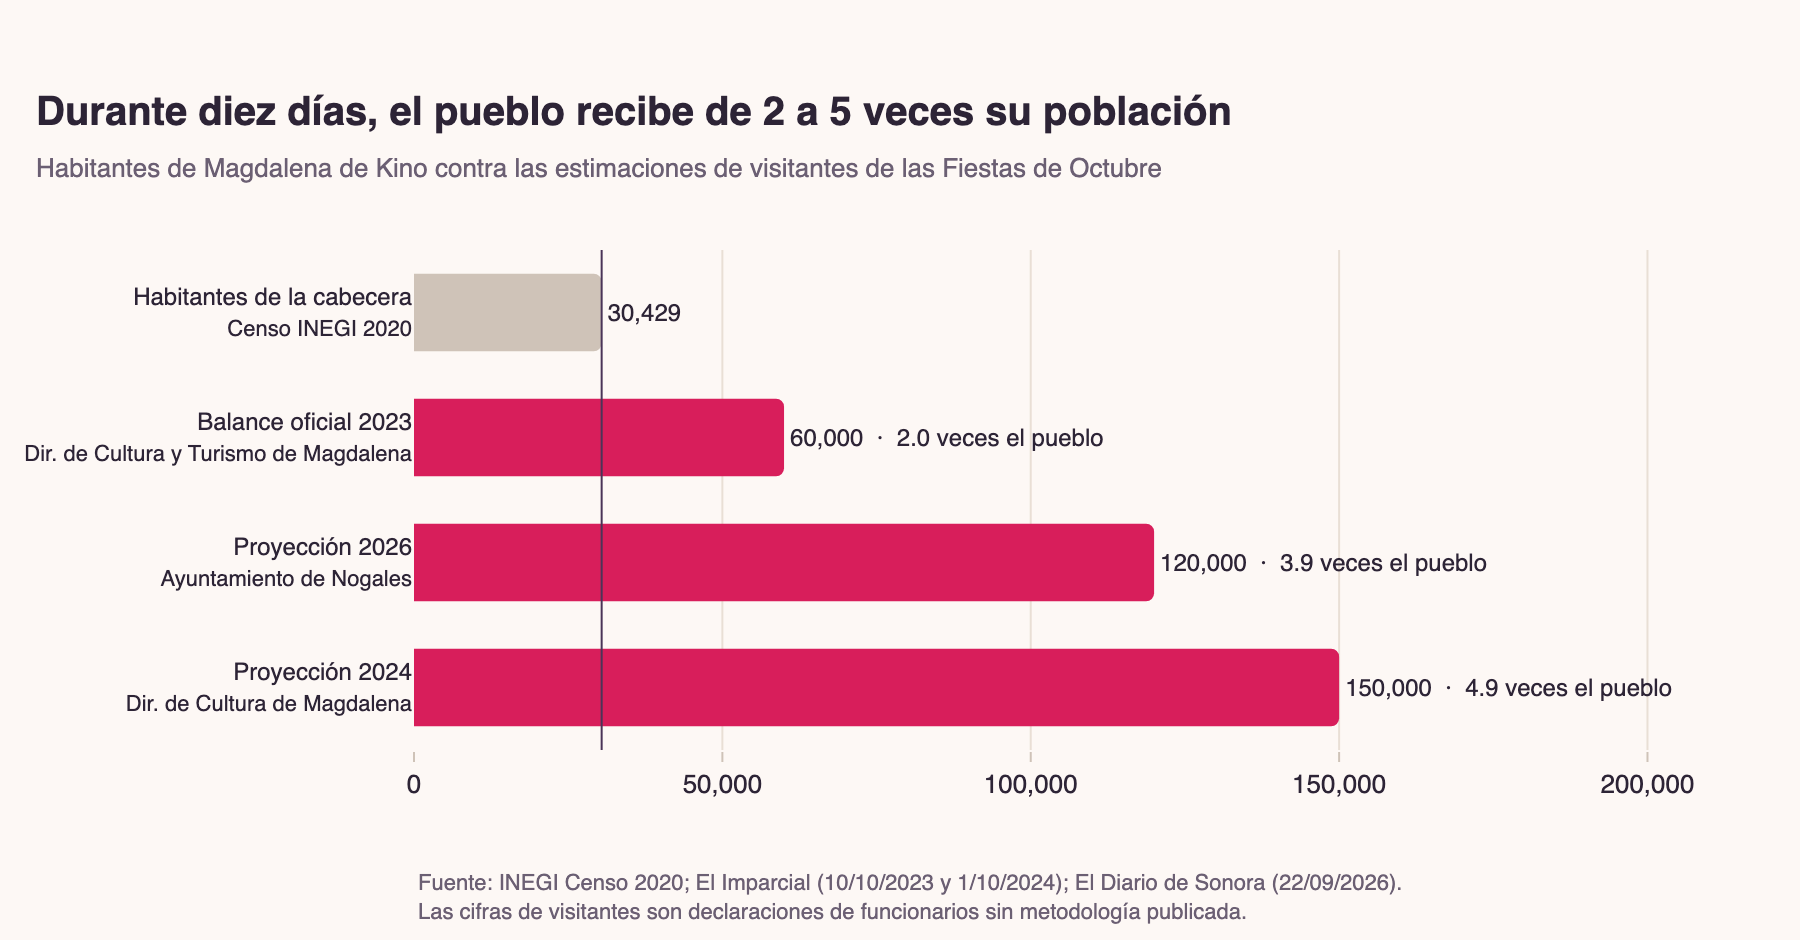

In [8]:
barras = pd.DataFrame([
    {"etiqueta": "Habitantes de la cabecera<br><span style='font-size:11px'>Censo INEGI 2020</span>", "valor": cab, "tipo": "poblacion"},
    {"etiqueta": "Balance oficial 2023<br><span style='font-size:11px'>Dir. de Cultura y Turismo de Magdalena</span>", "valor": 60000, "tipo": "estimacion"},
    {"etiqueta": "Proyección 2026<br><span style='font-size:11px'>Ayuntamiento de Nogales</span>", "valor": 120000, "tipo": "estimacion"},
    {"etiqueta": "Proyección 2024<br><span style='font-size:11px'>Dir. de Cultura de Magdalena</span>", "valor": 150000, "tipo": "estimacion"},
]).iloc[::-1]
barras["texto"] = [
    f"{v:,}" if t == "poblacion" else f"{v:,}  ·  {v / cab:.1f} veces el pueblo"
    for v, t in zip(barras["valor"], barras["tipo"])
]
fig = go.Figure(go.Bar(
    x=barras["valor"], y=barras["etiqueta"], orientation="h",
    marker=dict(color=[tema.NEUTRO if t == "poblacion" else tema.PROTAGONISTA for t in barras["tipo"]],
                line=dict(width=0), cornerradius=4),
    text=barras["texto"], textposition="outside", textfont=dict(color=tema.TEXTO, size=12),
    hovertemplate="%{y}<br><b>%{x:,} personas</b><extra></extra>", width=0.62,
))
fig.add_vline(x=cab, line=dict(color=tema.CONTORNO, width=1))
fig.update_layout(
    title=tema.titulo("Durante diez días, el pueblo recibe de 2 a 5 veces su población",
                      "Habitantes de Magdalena de Kino contra las estimaciones de visitantes de las Fiestas de Octubre"),
    xaxis=dict(range=[0, 215000], tickformat=",", showgrid=True, gridcolor=tema.CUADRICULA, title=None),
    yaxis=dict(tickfont=dict(size=12)),
    bargap=0.35, height=470, showlegend=False,
)
fig.update_layout(margin=dict(l=20, r=30))
tema.nota_fuente(fig, "Fuente: INEGI Censo 2020; El Imparcial (10/10/2023 y 1/10/2024); El Diario de Sonora (22/09/2026).<br>Las cifras de visitantes son declaraciones de funcionarios sin metodología publicada.")
tema.mostrar(fig, "03_multiplicador_poblacional")

**Lectura:** aun con la estimación más conservadora hay casi dos visitantes por habitante. La barra gris es la única medida con método; las magenta son lo mejor que hay.

## Conclusiones

- Multiplicador de **~2x a ~5x** con el denominador principal; de 1.7x a 5x con cualquier denominador razonable.
- El rango depende mucho más de qué estimación de visitantes se crea que de la población usada.
- La capacidad formal es mínima: con 60 mil visitantes, más de 4,600 por cada hotel o motel registrado.

In [9]:
sensibilidad.to_csv(config.DIR_PROCESSED / "multiplicador_sensibilidad.csv", index=False)
capacidad.to_csv(config.DIR_PROCESSED / "capacidad_alojamiento.csv", index=False)